# Breast Cancer Winsconsin (Diagnostic)
Classify a tumor as malignant or benign based on the features in the dataset

In [27]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

## Data Loading

In [28]:
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 

X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# M = 1, B = 0
y = y["Diagnosis"].map({"B": 0, "M": 1}).to_frame()

In [29]:
# features
X.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [30]:
# targets
y.head()

,Diagnosis
0,1
1,1
2,1
3,1
4,1


## Splitting into Training Data and Test Data

In [31]:
X_training, X_test, y_training, y_test = train_test_split(X, y, test_size=0.25)

In [32]:
X_training.shape, y_training.shape

((426, 30), (426, 1))

In [33]:
 X_test.shape, y_test.shape

((143, 30), (143, 1))

### Features Normalize

In [34]:
scaler = StandardScaler()
X_training = scaler.fit_transform(X_training)
X_test = scaler.transform(X_test)

## Neural Network Structure

We choose 16 neurons for hidden layer because the input layer has 30 neurons and the output layer has 1 neuron ( binary classification ). So, (30 + 1)/2 = 15.5 which approximated for 16.

Since this is a binary classification problem, we use the sigmoid activation function for the output layer.

In [35]:
neural_network = Sequential([
    tf.keras.Input(shape=(30,)),
    tf.keras.layers.Dense(units=16, activation='relu', kernel_initializer='random_uniform'),
    tf.keras.layers.Dense(units=1, activation='sigmoid')
])

neural_network.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

- 30 neurons in the input layer * 16 neurons in the hidden layer = 480 neurons 

    496 params - 480 = 16, which is the bias introduction in the hidden layer

- 17 params = 16 neurons in hidden layer connected in a only neuron of output + a bias

### Representation

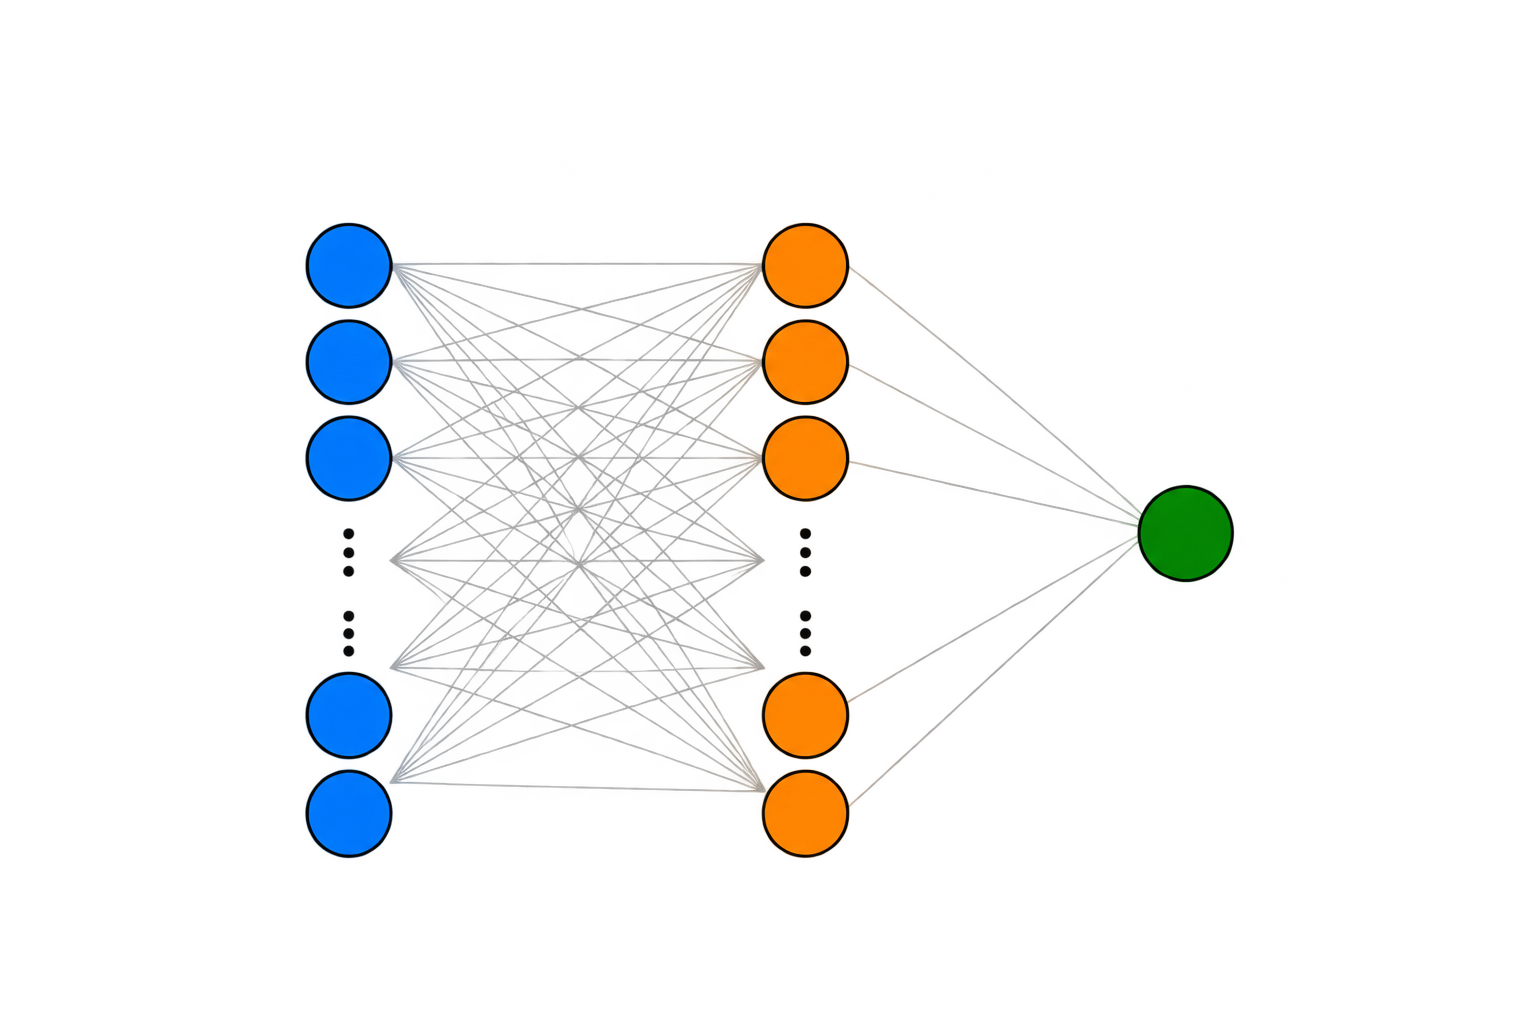

### Params Configuration

In [36]:
neural_network.compile(optimizer="adam", loss="binary_crossentropy", metrics=["binary_accuracy"])

In [37]:
neural_network.fit(X_training, y_training, batch_size=10, epochs=100)

Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - binary_accuracy: 0.8803 - loss: 0.4806  
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9366 - loss: 0.2596
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9484 - loss: 0.1820
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9624 - loss: 0.1439
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9718 - loss: 0.1220
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9742 - loss: 0.1079
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9812 - loss: 0.0985
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0908
Epoch 9/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0858
Epoch 10/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836 - loss: 0.0818
Epoch 11/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - binary_accuracy: 0.9836

The accuracy values ​​above are being calculated for the training set itself, which is not ideal. To do this correctly, we will use the test set.

In [38]:
predicteds = neural_network.predict(X_test)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


In [39]:
predicteds

array([[2.06841520e-04],
       [1.00000000e+00],
       [4.14676060e-06],
       [8.56342922e-06],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.62592997e-08],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.00000000e+00],
       [1.00000000e+00],
       [7.38263056e-02],
       [1.00000000e+00],
       [2.39675160e-06],
       [1.00000000e+00],
       [9.99999523e-01],
       [3.45551098e-06],
       [1.50256608e-06],
       [4.97090891e-02],
       [4.20134427e-07],
       [7.44575300e-13],
       [1.00000000e+00],
       [1.18825515e-03],
       [1.00000000e+00],
       [9.99304295e-01],
       [1.00000000e+00],
       [3.50852963e-04],
       [1.47257117e-06],
       [1.85769983e-04],
       [2.92370707e-04],
       [1.00000000e+00],
       [9.31845477e-07],
       [1.00000000e+00],
       [3.98198469e-03],
       [8.43338016e-03],
       [8.06544995e-06],
       [2.31470484e-02],
       [9.94093163e-09],
       [5.14897227e-04],
       [7.63560965e-05],


In [40]:
predicteds = (neural_network.predict(X_test) > 0.5).astype(int)
predicteds

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


array([[0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [1],
    

In [41]:
accuracy_score(y_test, predicteds)

0.986013986013986

In [42]:
confusion_matrix = confusion_matrix(y_test, predicteds)

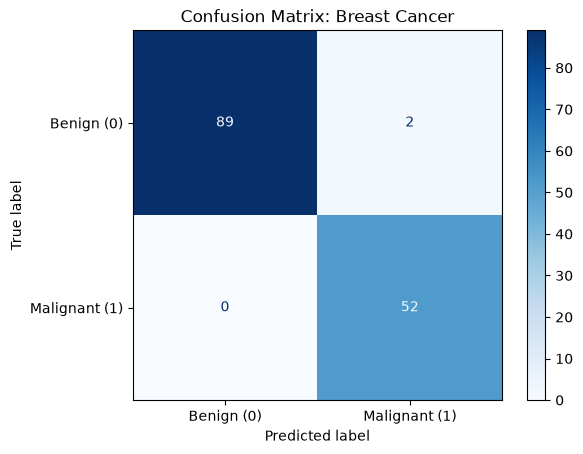

In [43]:
disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix, display_labels=["Benign (0)", "Malignant (1)"])
disp.plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix: Breast Cancer")
plt.show()